# Bivariate and Multivariate Analysis

## Part A: Quick Data Audit

**Load and Shape**

In [1]:
import pandas as pd

df = pd.read_csv('../data/interim/f1_results_interim.csv')

print('Shape:', df.shape)

Shape: (25850, 16)


**Column titles and data types**

In [2]:
print('\nColumns and dtypes:')
print(df.dtypes)


Columns and dtypes:
season                int64
round                 int64
race_name               str
driver_id               str
driver_name             str
constructor_id          str
constructor             str
grid                  int64
position              int64
points              float64
laps                  int64
status                  str
time                    str
fastest_lap             str
fastest_lap_rank    float64
finished               bool
dtype: object


**Missing value check**

In [3]:
print('\nMissing values per column:')
print(df.isna().sum())


Missing values per column:
season                  0
round                   0
race_name               0
driver_id               0
driver_name             0
constructor_id          0
constructor             0
grid                    0
position                0
points                  0
laps                    0
status                  0
time                17496
fastest_lap         17065
fastest_lap_rank    17065
finished                0
dtype: int64


**Describe**

In [4]:
print('\nDescriptive stats (numeric columns):')
df.describe()


Descriptive stats (numeric columns):


,season,round,grid,position,points,laps,fastest_lap_rank
count,25850.000000,25850.000000,25850.000000,25850.000000,25850.000000,25850.000000,8785.000000
mean,1992.700619,8.622166,11.717950,11.916983,2.162792,48.891180,10.621172
std,20.514022,5.174343,6.873079,6.869874,4.540700,27.907947,5.932522
min,1950.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,1977.000000,4.000000,6.000000,6.000000,0.000000,30.000000,6.000000
50%,1993.000000,8.000000,11.000000,12.000000,0.000000,53.000000,11.000000
75%,2011.000000,13.000000,17.000000,17.000000,2.000000,67.000000,16.000000
max,2026.000000,24.000000,34.000000,39.000000,50.000000,200.000000,24.000000


**Targets vs predictors:** `position`, `points` and `finished` are the outcomes - what you'd want to predict. `grid`, `season`, `round` and the constructor/driver columns are the inputs. Note that `points` and `fastest_lap_rank` are only known after the race, so using them as predictors would leak the result.

## Part B: Bivariate Analysis

Two pairs: grid vs points (should be strong) and laps vs points (not sure - could be weak or nonlinear).

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Preprocessing: use the df already loaded; keep only the columns needed for Part B
# grid == 0 rows are not real starting positions (mostly 'Withdrew', some Accident/
# Injury/Disqualified drivers who never took the grid)
cleanDF = df.loc[df['grid'] != 0, ['grid', 'points', 'laps', 'status']].copy()
print('Rows dropped (grid == 0):', (df['grid'] == 0).sum())
print('df_clean shape:', cleanDF.shape)

Rows dropped (grid == 0): 266
df_clean shape: (25584, 4)


**Pair 1: grid vs points (strong relationship expected)**


Expect a clear negative relationship: start further up the grid, score more points.

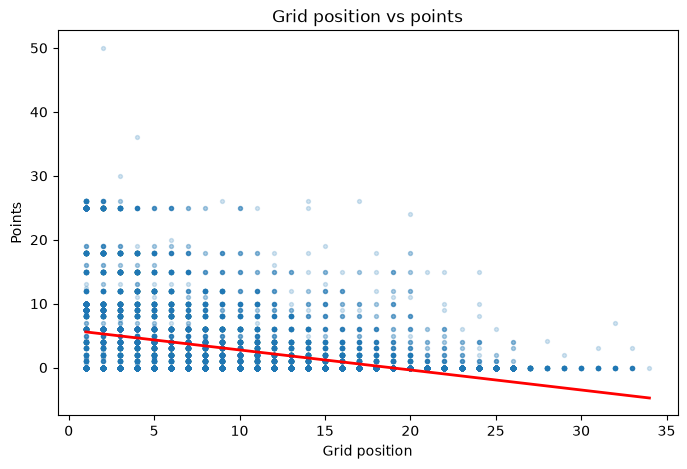

Covariance : -14.50   
Pearson r  : -0.468
Spearman   : -0.530
r2         : 0.219


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cleanDF['grid'], cleanDF['points'], alpha=0.2, s=8)

m, b = np.polyfit(cleanDF['grid'], cleanDF['points'], 1)
x = np.linspace(cleanDF['grid'].min(), cleanDF['grid'].max(), 100)
ax.plot(x, m * x + b, color='red', linewidth=2, label=f'Linear fit: y = {m:.3f}x + {b:.2f}')
ax.set_xlabel('Grid position')
ax.set_ylabel('Points')
ax.set_title('Grid position vs points')
plt.show()

g, p = cleanDF['grid'], cleanDF['points']
print(f'Covariance : {g.cov(p):.2f}   ')
print(f'Pearson r  : {g.corr(p):.3f}')
print(f'Spearman   : {g.rank().corr(p.rank()):.3f}')
print(f'r2         : {g.corr(p)**2:.3f}')

**Interpretation:** r2 = 0.219 means that only roughly 22% of the variance in points is linearly explained by grid. Spearman (-0.530) is noticeably stronger than Pearson (-0.468), suggesting the relationship is not purely linear.

**Pair 2: laps vs points (uncertain relationship expected)**

Not sure about this one - laps completed depends on race distance (varies a lot by era/circuit) and on whether the car finishes at all.

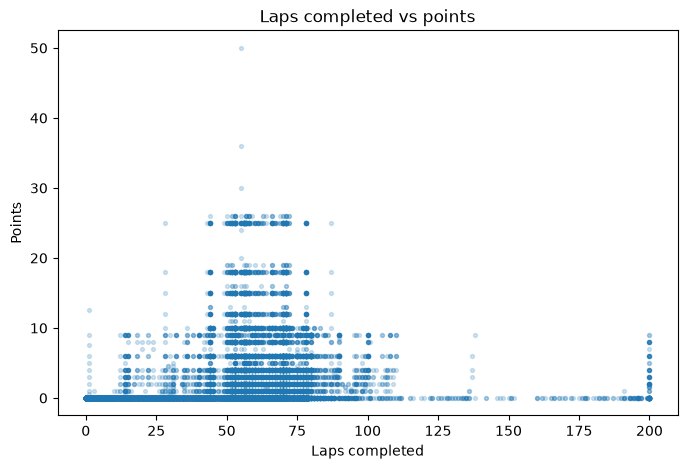

Covariance : 28.29
Pearson r  : 0.224
Spearman   : 0.389


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cleanDF['laps'], cleanDF['points'], alpha=0.2, s=8)
ax.set_xlabel('Laps completed')
ax.set_ylabel('Points')
ax.set_title('Laps completed vs points')
plt.show()

l = cleanDF['laps'] # p is df_clean['points']
print(f'Covariance : {l.cov(p):.2f}')
print(f'Pearson r  : {l.corr(p):.3f}')
print(f'Spearman   : {l.rank().corr(p.rank()):.3f}')

**Interpretation:** the Pearson/Spearman gap here (0.22 vs 0.39) is larger than in Pair 1 (-0.47 vs -0.53) - good evidence this relationship is monotonic but nonlinear, which is exactly why this pair was chosen.

**Outlier / nonlinearity check (Pair 2)**

Grid has essentially no real outliers under the IQR rule, so this check is run on laps instead. Method: IQR rule on laps.

In [8]:
q1, q3 = cleanDF['laps'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}')
print(f'Outlier bounds: laps < {lower:.0f} or laps > {upper:.0f}')

outliers = cleanDF[(cleanDF['laps'] < lower) | (cleanDF['laps'] > upper)]
print(f'Rows flagged: {len(outliers)} ({len(outliers) / len(cleanDF) * 100:.1f}%)')

no_out = cleanDF[(cleanDF['laps'] >= lower) & (cleanDF['laps'] <= upper)]
r_with = cleanDF['laps'].corr(cleanDF['points'])
r_without = no_out['laps'].corr(no_out['points'])
print(f'Pearson r with outliers   : {r_with:.3f}')
print(f'Pearson r without outliers: {r_without:.3f}  (+{r_without - r_with:.3f})')

Q1 = 31, Q3 = 67, IQR = 36
Outlier bounds: laps < -23 or laps > 121
Rows flagged: 263 (1.0%)
Pearson r with outliers   : 0.224
Pearson r without outliers: 0.273  (+0.049)


The Pearson correlation increases from 0.224 to 0.273 once the flagged long-race rows are removed. These are almost entirely very long races from the 1950s-60s, which ran far more laps than modern races. This suggests those older high-lap races add noise rather than drive the relationship - under modern race formats, laps completed is a somewhat clearer (though still weak) predictor of points than the full dataset suggests.

## Part C: Multivariate Analysis

**Correlation matrix (numeric features)**

Same grid != 0 filter as Part B

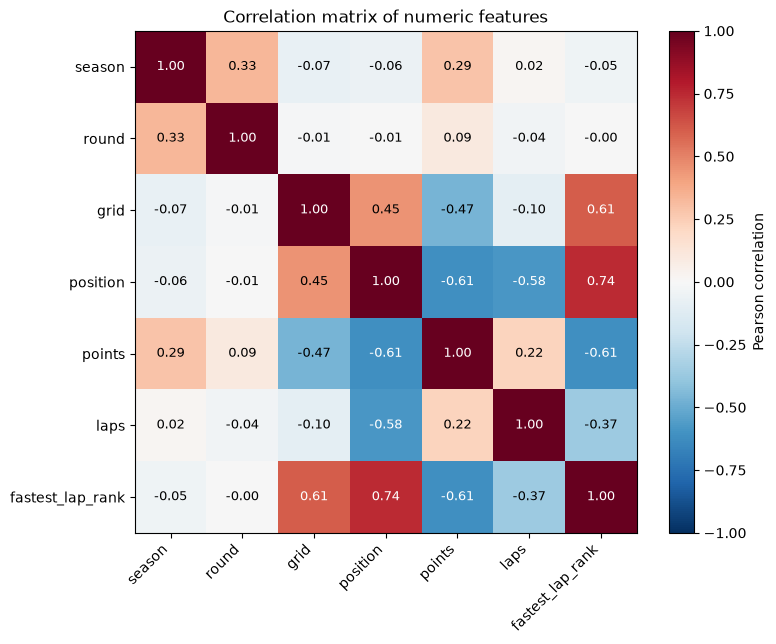

Top 3 strongest positive correlations:
            var1     var2        r
fastest_lap_rank position 0.743259
fastest_lap_rank     grid 0.608711
            grid position 0.450325
Top 3 strongest negative correlations:
            var1     var2         r
          points position -0.611511
fastest_lap_rank   points -0.611337
            laps position -0.583218


In [9]:
num_cols = ['season', 'round', 'grid', 'position', 'points', 'laps', 'fastest_lap_rank']
numDF = df.loc[df['grid'] != 0, num_cols]
corr = numDF.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticks(range(len(num_cols)))
ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Correlation matrix of numeric features')
plt.tight_layout()
plt.show()

pairs = (corr.where(~np.eye(len(num_cols), dtype=bool))
         .stack().rename('r').reset_index()
         .rename(columns={'level_0': 'var1', 'level_1': 'var2'}))
pairs = pairs[pairs['var1'] < pairs['var2']]  # drop mirrored duplicates
top_pos = pairs.sort_values('r', ascending=False).head(3)
top_neg = pairs.sort_values('r').head(3)
print('Top 3 strongest positive correlations:')
print(top_pos.to_string(index=False))
print('Top 3 strongest negative correlations:')
print(top_neg.to_string(index=False))

**Interpretation:** The strongest correlations all involve `position`, which acts as a hub: `points` (r = -0.61), `fastest_lap_rank` (r = 0.74) and `grid` (r = 0.45). Because `points`, `fastest_lap_rank` and `position` all encode the same underlying outcome (how well a driver raced), using them together in a model would create multicollinearity risk. Note that the `fastest_lap_rank` correlations are computed only over 2004+ rows, since the column is missing before then. In contrast, `grid`-`laps` (r = -0.10) is near zero: qualifying position does not determine how far a driver gets.

**Scaling/normalization impact**

`season` (~1950-2026), `laps` (0-200) and `points` (0-50) live on noticeably different scales.

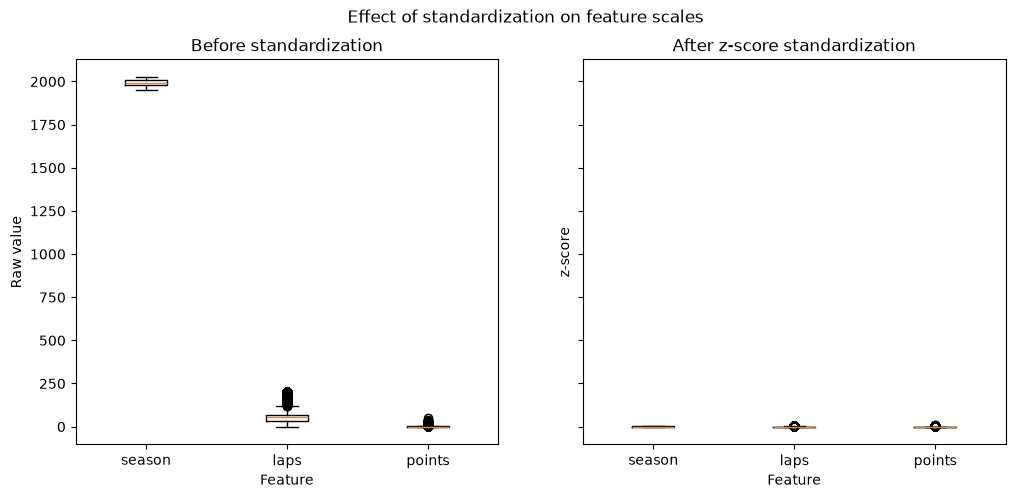

,mean_before,std_before,min_before,max_before,mean_after,std_after,min_after,max_after
season,1992.835,20.441,1950.0,2026.0,0.0,1.0,-2.096,1.622
laps,49.302,27.670,0.0,200.0,-0.0,1.0,-1.782,5.446
points,2.184,4.558,0.0,50.0,0.0,1.0,-0.479,10.489


In [10]:
features = ['season', 'laps', 'points']
raw = numDF[features]
z = (raw - raw.mean()) / raw.std()  # z-score standardization

summary = raw.agg(['mean', 'std', 'min', 'max']).T
summary = summary.join(z.agg(['mean', 'std', 'min', 'max']).T,
                       lsuffix='_before', rsuffix='_after')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].boxplot([raw[c] for c in features], tick_labels=features)
axes[0].set_xlabel('Feature')
axes[0].set_ylabel('Raw value')
axes[0].set_title('Before standardization')
axes[1].boxplot([z[c] for c in features], tick_labels=features)
axes[1].set_xlabel('Feature')
axes[1].set_ylabel('z-score')
axes[1].set_title('After z-score standardization')
fig.suptitle('Effect of standardization on feature scales')
plt.show()

summary.round(3)

**Why scaling matters:** distance- and variance-based methods (PCA, k-means) get dominated by whatever feature has the biggest numbers unless everything is on the same scale. After z-scoring all three features contribute comparably - shapes unchanged.

**C3 - Missing values: drop vs impute**

`fastest_lap_rank` is the only column with real missing values (~66%) - and the missingness is structural: no fastest-lap data before 2004.

In [11]:
pair_cols = ['fastest_lap_rank', 'position']
pair = numDF[pair_cols]
print(f"Missing fastest_lap_rank: {pair['fastest_lap_rank'].isna().sum()} "
      f"({pair['fastest_lap_rank'].isna().mean() * 100:.1f}%) of {len(pair)} rows")
print('Earliest season with a fastest_lap_rank value:',
      int(numDF.loc[numDF['fastest_lap_rank'].notna(), 'season'].min()))

# Approach 1: drop missing rows
dropped = pair.dropna()
r_drop = dropped['fastest_lap_rank'].corr(dropped['position'])

# Approach 2: mean imputation
mean_imp = pair.fillna(pair.mean())
r_mean = mean_imp['fastest_lap_rank'].corr(mean_imp['position'])

# Approach 3: median imputation
median_imp = pair.fillna(pair.median())
r_median = median_imp['fastest_lap_rank'].corr(median_imp['position'])

print(f'Pearson r (rows kept: {len(dropped)}):   drop   -> {r_drop:.3f}')
print(f'Pearson r (rows kept: {len(mean_imp)}):   mean   -> {r_mean:.3f}')
print(f'Pearson r (rows kept: {len(median_imp)}): median -> {r_median:.3f}')

Missing fastest_lap_rank: 16844 (65.8%) of 25584 rows
Earliest season with a fastest_lap_rank value: 2004
Pearson r (rows kept: 8740):   drop   -> 0.743
Pearson r (rows kept: 25584):   mean   -> 0.380
Pearson r (rows kept: 25584): median -> 0.386


Dropping rows is clearly more stable here. The drop-row estimate (r = 0.74) reflects real observations, while mean/median imputation fills roughly 66% of rows with a single constant that has no relationship to `position`, crushing the correlation to roughly 0.38. Since the missingness is structural (pre-2004 races never recorded fastest laps) rather than random, imputation is inappropriate; dropping or restricting the analysis to 2004+ is the honest choice.